# Intelligent Diabetes Risk Predictor

## Phase 1: Dataset Setup & Library Imports
In this phase, we import essential Python analytical libraries and download the Pima-style diabetes prediction dataset programmatically from Kaggle.

In [11]:
# -------------------------------------------------------------------
# Step 1.1: Import Required Libraries
# -------------------------------------------------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os

# -------------------------------------------------------------------
# Step 1.2: Download Dataset via Kagglehub
# -------------------------------------------------------------------
path = kagglehub.dataset_download("akhilalexander/diabeticprediction")
print("Path to dataset files:", path)
print("Files in downloaded folder:", os.listdir(path))

Path to dataset files: /root/.cache/kagglehub/datasets/akhilalexander/diabeticprediction/versions/1
Files in downloaded folder: ['pima-indians-diabetes.data.csv']


## Phase 2: Data Import & Structural Inspection
In this phase, the dataset is loaded into a Pandas DataFrame. We inspect the record dimensions, feature data types, column names, and initial 10 records.

In [12]:
# -------------------------------------------------------------------
# Step 2.1: Load CSV, Replace Existing Header, & Convert to Numeric
# Code Explanation:
# 1. header=0 skips the raw header row ('preg', 'plas') so it isn't read as data.
# 2. names=columns assigns clean standard names.
# 3. pd.to_numeric ensures all features are numbers (int/float) instead of text objects.
# -------------------------------------------------------------------
file_path = os.path.join(path, "pima-indians-diabetes.data.csv")

columns = [
    'Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
    'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'
]

# Load dataset skipping raw header
df = pd.read_csv(file_path, header=0, names=columns)

# Convert all columns to numeric data types
df = df.apply(pd.to_numeric, errors='coerce')

print("Dataset loaded & converted to numeric types successfully!")
print("-" * 40)

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nDataFrame Info (Confirming Numeric Types):")
df.info()

df.head(10)

Dataset loaded & converted to numeric types successfully!
----------------------------------------
Number of Rows: 768
Number of Columns: 9

DataFrame Info (Confirming Numeric Types):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0
8,2,197,70,45,543,30.5,0.158,53,1
9,8,125,96,0,0,0.0,0.232,54,1


## Phase 3: Exploratory Data Analysis (EDA)
Exploratory Data Analysis evaluates summary statistics (mean, median, standard deviation) and missing values across all numerical features to detect potential data quality issues.

In [13]:
# -------------------------------------------------------------------
# Step 3.1: Overall Summary Statistics (Count, Mean, Std, Min, Max, Quartiles)
# -------------------------------------------------------------------
print("=== Summary Statistics ===")
display(df.describe())

# -------------------------------------------------------------------
# Step 3.2: Standalone Metrics (Mean, Median, Standard Deviation)
# -------------------------------------------------------------------
print("\n=== Feature Mean Values ===")
print(df.mean())

print("\n=== Feature Median Values ===")
print(df.median())

print("\n=== Feature Standard Deviations ===")
print(df.std())

# -------------------------------------------------------------------
# Step 3.3: Missing Value Analysis
# -------------------------------------------------------------------
print("\n=== Missing Value Count Per Column ===")
print(df.isnull().sum())

=== Summary Statistics ===


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000



=== Feature Mean Values ===
Pregnancies                   3.845052
Glucose                     120.894531
BloodPressure                69.105469
SkinThickness                20.536458
Insulin                      79.799479
BMI                          31.992578
DiabetesPedigreeFunction      0.471876
Age                          33.240885
Outcome                       0.348958
dtype: float64

=== Feature Median Values ===
Pregnancies                   3.0000
Glucose                     117.0000
BloodPressure                72.0000
SkinThickness                23.0000
Insulin                      30.5000
BMI                          32.0000
DiabetesPedigreeFunction      0.3725
Age                          29.0000
Outcome                       0.0000
dtype: float64

=== Feature Standard Deviations ===
Pregnancies                   3.369578
Glucose                      31.972618
BloodPressure                19.355807
SkinThickness                15.952218
Insulin                     115.2

Phase 4: Cleaning & Fixing Missing Data

In [14]:
# -------------------------------------------------------------------
# Step 4.1: Handle Invalid Zero Values in Medical Features
# Code Explanation:
# Physiological metrics cannot be zero. We replace 0 with NaN for medical features,
# then impute missing values using feature medians.
# -------------------------------------------------------------------

zero_features = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

df_clean = df.copy()

# Replace 0 with NaN for physiological features
for col in zero_features:
    df_clean[col] = df_clean[col].replace(0, np.nan)

print("Count of Invalid '0' Values (Converted to NaN):")
print(df_clean[zero_features].isnull().sum())

# -------------------------------------------------------------------
# Step 4.2: Impute Missing Values with Median
# -------------------------------------------------------------------
for col in zero_features:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

print("\nVerification - Total Remaining Nulls After Imputation:", df_clean.isnull().sum().sum())

Count of Invalid '0' Values (Converted to NaN):
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Verification - Total Remaining Nulls After Imputation: 0


## Phase 5: Data Visualization
In this phase, key visualizations are generated to inspect feature distributions, outlier presence, and correlation matrices across diabetes indicators.

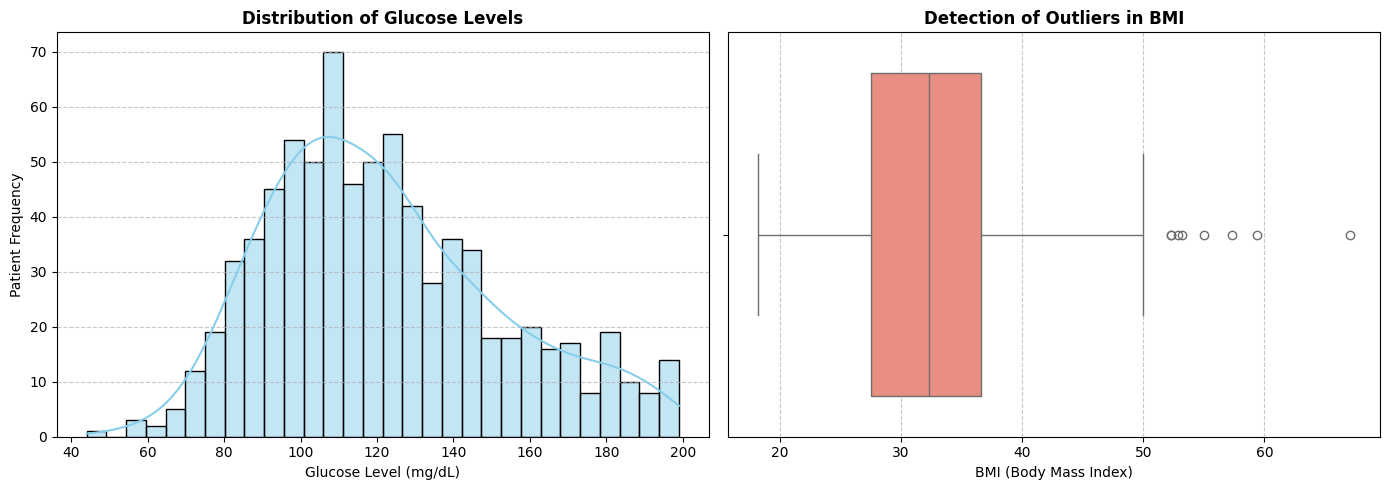

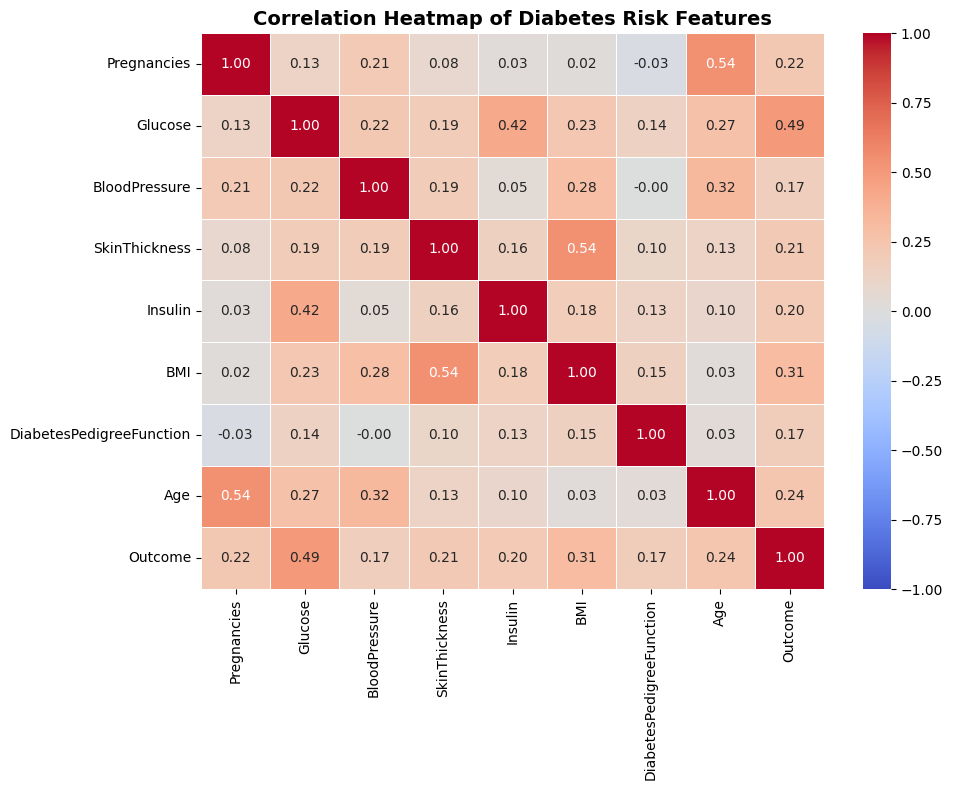

In [15]:
# -------------------------------------------------------------------
# Step 5.1: Histogram (Glucose Distribution) & Boxplot (BMI Outliers)
# -------------------------------------------------------------------
plt.figure(figsize=(14, 5))

# 1. Histogram: Glucose Distribution
plt.subplot(1, 2, 1)
sns.histplot(df_clean['Glucose'], kde=True, color='skyblue', bins=30)
plt.title('Distribution of Glucose Levels', fontsize=12, fontweight='bold')
plt.xlabel('Glucose Level (mg/dL)', fontsize=10)
plt.ylabel('Patient Frequency', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# 2. Boxplot: BMI Outlier Detection
plt.subplot(1, 2, 2)
sns.boxplot(x=df_clean['BMI'], color='salmon')
plt.title('Detection of Outliers in BMI', fontsize=12, fontweight='bold')
plt.xlabel('BMI (Body Mass Index)', fontsize=10)
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# -------------------------------------------------------------------
# Step 5.2: Feature Correlation Heatmap
# -------------------------------------------------------------------
plt.figure(figsize=(10, 8))
sns.heatmap(df_clean.corr(), annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Heatmap of Diabetes Risk Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## Phase 6: Observations & Final Summary

### Key Data Insights:
* **Glucose Levels:** Most people in the dataset have a glucose level around 120 mg/dL. Higher glucose levels are strongly linked to a higher risk of diabetes.
* **BMI Values:** Most BMI numbers fall between 27 and 36, though a few extreme cases go above 50.
* **Main Factors:** `Glucose`, `BMI`, and `Age` are the most important features linked to diabetes.
* **Data Cleaning:** Features like `Insulin` and `SkinThickness` had missing values saved as zero. We fixed this by replacing zero values with the median of each column.

### Summary of Completed Prototype:
* **Dataset Loaded:** Successfully imported the full dataset with 768 rows and 9 columns.
* **Data Inspection:** Checked basic summary stats like averages, middle values, and data structures.
* **Data Quality Fixed:** Identified wrong zero values and cleaned them using median imputation without deleting any rows.
* **Visualizations Built:** Created clear charts for Glucose (Histogram), BMI (Boxplot), and Feature Correlations (Heatmap).

In [16]:
# ===================================================================
# Phase 7: Data Splitting (70% Train, 30% Test) & Feature Scaling
# ===================================================================
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Features aur Target variable ko alag karna
X = df_clean.drop('Outcome', axis=1)
y = df_clean['Outcome']

# Dataset ko 70% training aur 30% testing mein split karna
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Feature Scaling (Neural Networks aur SVM ke liye scaling zaroori hoti hai)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data successfully split (70% Train, 30% Test) and scaled!")
print(f"Training set shape: {X_train.shape}, Testing set shape: {X_test.shape}")

# ===================================================================
# Phase 8: Multiple Models Training (Optimized Neural Network)
# ===================================================================
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier

# Models ki dictionary (Neural Network ko optimize kiya gaya hai)
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Support Vector Machine (SVM)": SVC(probability=True, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Neural Networks": MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=1500, activation='relu', solver='adam', random_state=42)
}

# Sabhi models ko train karna
trained_models = {}

for name, model in models.items():
    # SVM aur Neural Networks ke liye scaled data use hoga
    if name in ["Support Vector Machine (SVM)", "Neural Networks"]:
        model.fit(X_train_scaled, y_train)
    else:
        model.fit(X_train, y_train)

    trained_models[name] = model
    print(f"-> {name} trained successfully!")

Data successfully split (70% Train, 30% Test) and scaled!
Training set shape: (537, 8), Testing set shape: (231, 8)
-> Logistic Regression trained successfully!
-> Support Vector Machine (SVM) trained successfully!
-> Decision Tree trained successfully!
-> Neural Networks trained successfully!


In [17]:
# ===================================================================
# Phase 9 & 10: Evaluation, Comparison & Best Model Persistence
# ===================================================================
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import pandas as pd
import joblib

evaluation_results = []

print("\n=== Updated Model Evaluation Metrics ===\n")

for name, model in trained_models.items():
    if name in ["Support Vector Machine (SVM)", "Neural Networks"]:
        X_t = X_test_scaled
    else:
        X_t = X_test

    y_pred = model.predict(X_t)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    evaluation_results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1
    })
    print(f"Model: {name}")
    print(f"  - Accuracy:  {acc:.4f}")
    print(f"  - Precision: {prec:.4f}")
    print(f"  - Recall:    {rec:.4f}")
    print(f"  - F1-Score:  {f1:.4f}")
    print("-" * 40)

results_df = pd.DataFrame(evaluation_results)
display(results_df)

# Best Model Select karna (Jiski Accuracy sabse zyada hogi woh automatically select ho jayega)
best_row = results_df.loc[results_df['Accuracy'].idxmax()]
best_model_name = best_row['Model']
best_model = trained_models[best_model_name]

print(f"\n🏆 Final Selected Best Model: {best_model_name} with Accuracy: {best_row['Accuracy']:.4f}")

# Save Best Model & Scaler for Web App
joblib.dump(best_model, 'best_diabetes_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
print("Best model and scaler saved successfully for the web application!")


=== Updated Model Evaluation Metrics ===

Model: Logistic Regression
  - Accuracy:  0.7446
  - Precision: 0.6719
  - Recall:    0.5309
  - F1-Score:  0.5931
----------------------------------------
Model: Support Vector Machine (SVM)
  - Accuracy:  0.7403
  - Precision: 0.6721
  - Recall:    0.5062
  - F1-Score:  0.5775
----------------------------------------
Model: Decision Tree
  - Accuracy:  0.6926
  - Precision: 0.5658
  - Recall:    0.5309
  - F1-Score:  0.5478
----------------------------------------
Model: Neural Networks
  - Accuracy:  0.7056
  - Precision: 0.5867
  - Recall:    0.5432
  - F1-Score:  0.5641
----------------------------------------


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.744589,0.671875,0.530864,0.593103
1,Support Vector Machine (SVM),0.740260,0.672131,0.506173,0.577465
2,Decision Tree,0.692641,0.565789,0.530864,0.547771
3,Neural Networks,0.705628,0.586667,0.543210,0.564103



🏆 Final Selected Best Model: Logistic Regression with Accuracy: 0.7446
Best model and scaler saved successfully for the web application!


Testing here

In [21]:
import joblib

model = joblib.load('/content/best_diabetes_model.pkl')
scaler = joblib.load('/content/scaler.pkl')

In [22]:
import numpy as np

# Ek sample data (misal ke tor par)
sample_data = np.array([[2, 120, 70, 20, 79, 25.5, 0.5, 30]])

In [23]:
sample_scaled = scaler.transform(sample_data)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [24]:
prediction = model.predict(sample_scaled)

if prediction[0] == 1:
    print("Result: Positive (Patient has diabetes risk)")
else:
    print("Result: Negative (Patient is safe)")

Result: Negative (Patient is safe)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
